# Bagging with Linear Regression on the California Housing Dataset

This notebook implements bagging from scratch. Several linear regression models are each trained on a bootstrap sample of the training set (sampled with replacement), and their predictions are averaged. The aim is to see how the number of models affects the training and test error.

In [1]:
#imports
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

## Data

The California Housing dataset has 20,640 districts with eight numeric features. The target is the median house value, in units of $100,000.

In [2]:
# loading the dataset
def load_dataset():
  reg_x, reg_y = fetch_california_housing(return_X_y = True)

  reg_data = np.concatenate((reg_x, np.array(reg_y).reshape(-1, 1)), axis = 1)

  cols = ["feature"+str(i) for i in range(1, 9)]
  cols = cols + ["price(target)"]

  reg_dataset = pd.DataFrame(data = reg_data, columns = cols)

  return reg_dataset

reg_dataset = load_dataset()
print("REGRESSION DATASET : \n", reg_dataset)

REGRESSION DATASET : 
        feature1  feature2  feature3  feature4  feature5  feature6  feature7  \
0        8.3252      41.0  6.984127  1.023810     322.0  2.555556     37.88   
1        8.3014      21.0  6.238137  0.971880    2401.0  2.109842     37.86   
2        7.2574      52.0  8.288136  1.073446     496.0  2.802260     37.85   
3        5.6431      52.0  5.817352  1.073059     558.0  2.547945     37.85   
4        3.8462      52.0  6.281853  1.081081     565.0  2.181467     37.85   
...         ...       ...       ...       ...       ...       ...       ...   
20635    1.5603      25.0  5.045455  1.133333     845.0  2.560606     39.48   
20636    2.5568      18.0  6.114035  1.315789     356.0  3.122807     39.49   
20637    1.7000      17.0  5.205543  1.120092    1007.0  2.325635     39.43   
20638    1.8672      18.0  5.329513  1.171920     741.0  2.123209     39.43   
20639    2.3886      16.0  5.254717  1.162264    1387.0  2.616981     39.37   

       feature8  price(targe

## Bootstrap Sampling

The data is split 80/20 into training and test sets. A bootstrap sample is then drawn from the training set with the same number of rows as the original. Because sampling is done with replacement, some rows appear several times and others are left out.

In [3]:
x=reg_dataset.drop("price(target)",axis=1)
y=reg_dataset["price(target)"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
def get_random_indices(x_train):
  indices=np.random.choice(len(x_train),size=len(x_train),replace=True) # draw indices with replacement: some rows repeat, others are left out
  return indices
indices=get_random_indices(x_train)
x_sample=x_train.iloc[indices]
y_sample=y_train.iloc[indices]
print(x_sample.shape)
print(y_sample.shape)

(16512, 8)
(16512,)


## Single Model

The first model is trained on one bootstrap sample. Its test MSE is about 0.56, which serves as the reference for the ensembles below.

In [4]:
# first model, trained on one bootstrap sample
model1=LinearRegression()
model1.fit(x_sample,y_sample)
y_pred=model1.predict(x_test)
print(f"Mean Squared Error: {mean_squared_error(y_test,y_pred)}")

Mean Squared Error: 0.5566206703967055


## Two Models

In [5]:
# second model; the two predictions are averaged
indices2=get_random_indices(x_train)
x_sample2=x_train.iloc[indices2]
y_sample2=y_train.iloc[indices2]
model2=LinearRegression()
model2.fit(x_sample2,y_sample2)
y_pred2=model2.predict(x_test)
y_pred_avg=(y_pred+y_pred2)/2
print(f"Mean Squared Error: {mean_squared_error(y_test,y_pred_avg)}")

Mean Squared Error: 0.5585220386512803


## Three Models

In [6]:
# third model, same steps again
indices3=get_random_indices(x_train)
x_sample3=x_train.iloc[indices3]
y_sample3=y_train.iloc[indices3]
model3=LinearRegression()
model3.fit(x_sample3,y_sample3)
y_pred3=model3.predict(x_test)
y_pred_avg=(y_pred+y_pred2+y_pred3)/3
print(f"Mean Squared Error: {mean_squared_error(y_test,y_pred_avg)}")

Mean Squared Error: 0.5583437226461768


## Four Models

In [7]:
indices4=get_random_indices(x_train)
x_sample4=x_train.iloc[indices4]
y_sample4=y_train.iloc[indices4]
model4=LinearRegression()
model4.fit(x_sample4,y_sample4)
y_pred4=model4.predict(x_test)
y_pred_avg=(y_pred+y_pred2+y_pred3+y_pred4)/4
print(f"Mean Squared Error: {mean_squared_error(y_test,y_pred_avg)}")

Mean Squared Error: 0.5622113601131784


Averaging two, three and four models does not improve on the single model. The test MSE stays between about 0.557 and 0.562, and the four-model average is slightly worse than the single model. Each added model brings almost no improvement.

## Effect of the Number of Models

The ensemble size is increased from 2 to 30 in steps of 2. For each size, the models are trained on separate bootstrap samples, and the training and test MSE of their averaged predictions are recorded.

Models : 2, Test MSE : 0.5550282526773529
Models : 4, Test MSE : 0.5583239221354283
Models : 6, Test MSE : 0.5606508100047229
Models : 8, Test MSE : 0.557329936056506
Models : 10, Test MSE : 0.5524021488335509
Models : 12, Test MSE : 0.5538384939659277
Models : 14, Test MSE : 0.5568397485652573
Models : 16, Test MSE : 0.5541361743821007
Models : 18, Test MSE : 0.5569352701522874
Models : 20, Test MSE : 0.5507366067852437
Models : 22, Test MSE : 0.5499735947080351
Models : 24, Test MSE : 0.5550261606700988
Models : 26, Test MSE : 0.548234213180454
Models : 28, Test MSE : 0.5531817481289999
Models : 30, Test MSE : 0.5566249119588988


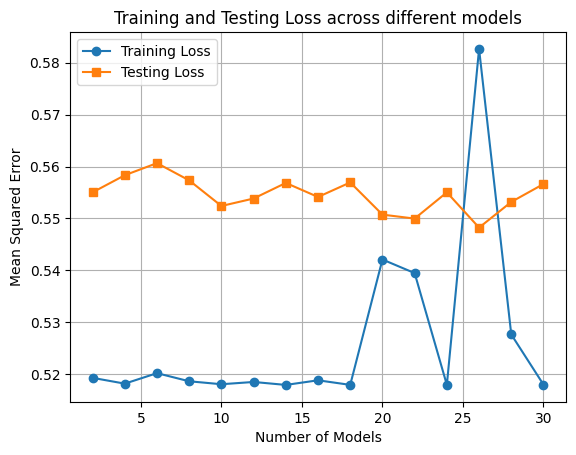

In [8]:
# for each ensemble size, train n models on separate bootstrap samples
model_counts=[]
train_loss=[]
test_loss=[]
for n in range(2,31,2):
  models=[]
  train_predictions=[]
  test_predictions=[]
  for i in range(n):
    indices=get_random_indices(x_train)
    x_sample=x_train.iloc[indices]
    y_sample=y_train.iloc[indices]
    model=LinearRegression()
    model.fit(x_sample,y_sample)
    models.append(model)
    train_predictions.append(model.predict(x_train))
    test_predictions.append(model.predict(x_test))

  # average the predictions of the n models
  avg_train_pred=np.mean(train_predictions,axis=0)
  avg_test_pred=np.mean(test_predictions,axis=0)
  train_mse=mean_squared_error(y_train,avg_train_pred)
  test_mse=mean_squared_error(y_test,avg_test_pred)
  model_counts.append(n)
  train_loss.append(train_mse)
  test_loss.append(test_mse)
  print(f"Models : {n}, Test MSE : {test_mse}")

#plot training and testing loss
plt.plot(model_counts,train_loss,label="Training Loss",marker="o")
plt.plot(model_counts,test_loss,label="Testing Loss",marker="s")
plt.title("Training and Testing Loss across different models")
plt.xlabel("Number of Models")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.legend()
plt.show()

The test MSE stays in a narrow band between about 0.548 and 0.561, with no clear downward trend as models are added. The training MSE sits mostly near 0.52, below the test MSE, but it jumps at some of the larger ensemble sizes, most clearly at 26 models, where it rises to about 0.58 and above the test MSE. These jumps are probably caused by extreme rows in the training data: when a bootstrap sample over- or under-represents them, the resulting model fits them badly. The test set does not show similar jumps.

## Conclusions

Bagging brought almost no improvement here. Bagging reduces variance, and linear regression has very little variance to reduce. With more than 16,000 rows in each bootstrap sample, every model learns almost the same line, so averaging them returns almost the same prediction.

Bagging would be expected to help more with an unstable model such as a deep decision tree, which would be a natural next experiment.